# Developer technology trends

This analysis uses the IBM course copy of the 2024 Stack Overflow survey,
a modified job-listings sample and an undated language-salary exercise page.
The examples describe their source samples. They are not live job-market or
salary estimates. Source links and licensing are in the repository README.

In [1]:
%matplotlib inline
from pathlib import Path
from html.parser import HTMLParser
from urllib.parse import urlencode
from urllib.request import urlopen
import importlib.util
import json
import os
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from plotly.subplots import make_subplots

ROOT = Path(__file__).resolve().parents[1] if '__file__' in globals() else Path.cwd()
while not (ROOT / 'src' / 'jobs_api.py').exists():
    if ROOT.parent == ROOT:
        raise FileNotFoundError('Run this notebook from the repository or notebooks directory.')
    ROOT = ROOT.parent
RAW = Path(os.environ.get('CAPSTONE_DATA_DIR', ROOT / 'data' / 'raw'))
DERIVED = ROOT / 'data' / 'derived'
REPORTS = ROOT / 'reports'
FIGURES = REPORTS / 'figures'
for directory in (DERIVED, FIGURES):
    directory.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(ROOT / 'src'))
from jobs_api import serve_jobs

plt.rcParams.update({'figure.dpi': 130, 'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.titleweight': 'bold'})

## Collect job counts through a local REST API

The API serves the downloaded course JSON on localhost. `CourseMatches`
reproduces case-sensitive substring matching in the supplied lab API.
`BoundedMatches` searches case-insensitively with word boundaries to separate
terms such as Java and JavaScript, or C and C++. Neither measure deduplicates
real-world advertisements beyond the identifiers provided in this sample.

In [2]:
jobs = json.loads((RAW / 'jobs.json').read_text(encoding='utf-8'))
technologies = ['C', 'C#', 'C++', 'Java', 'JavaScript', 'Python', 'Scala',
                'Oracle', 'SQL Server', 'MySQL Server', 'PostgreSQL', 'MongoDB']
locations = ['Los Angeles', 'New York', 'San Francisco', 'Washington DC',
             'Seattle', 'Austin', 'Detroit']
technology_rows, location_rows = [], []
with serve_jobs(jobs) as api:
    def api_count(field, term, mode='course'):
        with urlopen(api + '/data?' + urlencode({field: term, 'mode': mode}), timeout=30) as response:
            return len(json.load(response))
    for technology in technologies:
        technology_rows.append([technology, api_count('Key Skills', technology),
                                api_count('Key Skills', technology, 'bounded')])
    for location in locations:
        location_rows.append([location, api_count('Location', location)])
job_counts = pd.DataFrame(technology_rows, columns=['Technology', 'CourseMatches', 'BoundedMatches'])
location_counts = pd.DataFrame(location_rows, columns=['Location', 'Jobs'])
job_counts.to_csv(DERIVED / 'job_technology_counts.csv', index=False)
location_counts.to_csv(DERIVED / 'job_location_counts.csv', index=False)
print(f'Job sample: {len(jobs):,} records. Unique IDs: {len({row["Id"] for row in jobs}):,}.')
print(job_counts.to_string(index=False))

Job sample: 27,005 records. Unique IDs: 27,005.
  Technology  CourseMatches  BoundedMatches
           C          13498             961
          C#            333             526
         C++            305             503
        Java           2609            1601
  JavaScript            355            2246
      Python           1173            1171
       Scala             33              89
      Oracle            784             899
  SQL Server            250             422
MySQL Server              0               0
  PostgreSQL             10              86
     MongoDB            174             208


## Scrape the course salary table

The HTML page has ten languages and average annual salaries in US dollars.
It does not provide a survey date, geography, sample size or methodology.
It is retained as a web-scraping exercise, separately from the 2024 survey.

In [3]:
class SalaryTableParser(HTMLParser):
    def __init__(self):
        super().__init__()
        self.rows, self.row, self.text = [], [], []
        self.in_cell = False

    def handle_starttag(self, tag, attrs):
        if tag == 'tr':
            self.row = []
        if tag in ('td', 'th'):
            self.in_cell, self.text = True, []

    def handle_data(self, text):
        if self.in_cell:
            self.text.append(text)

    def handle_endtag(self, tag):
        if tag in ('td', 'th'):
            self.row.append(''.join(self.text).strip())
            self.in_cell = False
        if tag == 'tr' and self.row:
            self.rows.append(self.row)

parser = SalaryTableParser()
parser.feed((RAW / 'Programming_Languages.html').read_text(encoding='utf-8'))
salary_table = pd.DataFrame(parser.rows[1:], columns=parser.rows[0])
salary_table = salary_table[['Language', 'Average Annual Salary']].rename(
    columns={'Average Annual Salary': 'AnnualSalaryUSD'})
salary_table['AnnualSalaryUSD'] = salary_table['AnnualSalaryUSD'].str.replace(r'[$,]', '', regex=True).astype(int)
salary_table.to_csv(DERIVED / 'popular-languages.csv', index=False)
print(salary_table.to_string(index=False))

  Language  AnnualSalaryUSD
    Python           114383
      Java           101013
         R            92037
Javascript           110981
     Swift           130801
       C++           113865
        C#            88726
       PHP            84727
       SQL            84793
        Go            94082


## Explore and clean the survey

Remove exact duplicate rows. Verify that remaining respondent IDs are unique.
Keep unanswered questions missing rather than replacing them with fabricated
responses. Preserve all respondents for technology analysis. Numeric salary
summaries use positive, nonmissing `ConvertedCompYearly` values supplied in
the dataset. Outliers are flagged for plotting but not deleted from the data.

In [4]:
raw = pd.read_csv(RAW / 'survey-data-with-duplicate.csv', low_memory=False)
duplicate_rows = int(raw.duplicated().sum())
survey = raw.drop_duplicates().copy()
if survey['ResponseId'].duplicated().any():
    raise ValueError('Conflicting records share a respondent ID. Resolve before counting.')
n = len(survey)
missing = pd.DataFrame({'Column': survey.columns,
                        'Missing': survey.isna().sum().to_numpy(),
                        'MissingPct': survey.isna().mean().to_numpy() * 100})
missing.to_csv(DERIVED / 'missing_values.csv', index=False)
compensation = pd.to_numeric(survey['ConvertedCompYearly'], errors='coerce')
positive_compensation = compensation.loc[compensation.gt(0)]
q1, q3 = positive_compensation.quantile([.25, .75])
lower, upper = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
iqr_inliers = positive_compensation.between(lower, upper)
quality = {
    'source_rows': len(raw), 'source_columns': raw.shape[1],
    'exact_duplicates_removed': duplicate_rows, 'respondents': n,
    'countries': int(survey['Country'].nunique()),
    'missing_country': int(survey['Country'].isna().sum()),
    'missing_compensation': int(compensation.isna().sum()),
    'positive_compensation_responses': len(positive_compensation),
    'median_annual_compensation_usd': float(positive_compensation.median()),
    'compensation_iqr_upper_usd': float(upper),
    'compensation_iqr_outliers': int((~iqr_inliers).sum()),
    'job_sample_records': len(jobs),
}
(DERIVED / 'data_quality.json').write_text(json.dumps(quality, indent=2), encoding='utf-8')
print(json.dumps(quality, indent=2))
print(survey[['Age', 'Country', 'RemoteWork', 'ConvertedCompYearly']].head().to_string(index=False))

{
  "source_rows": 65457,
  "source_columns": 114,
  "exact_duplicates_removed": 20,
  "respondents": 65437,
  "countries": 185,
  "missing_country": 6507,
  "missing_compensation": 42002,
  "positive_compensation_responses": 23435,
  "median_annual_compensation_usd": 65000.0,
  "compensation_iqr_upper_usd": 220860.75,
  "compensation_iqr_outliers": 978,
  "job_sample_records": 27005
}
               Age                                              Country RemoteWork  ConvertedCompYearly
Under 18 years old                             United States of America     Remote                  NaN
   35-44 years old United Kingdom of Great Britain and Northern Ireland     Remote                  NaN
   45-54 years old United Kingdom of Great Britain and Northern Ireland     Remote                  NaN
   18-24 years old                                               Canada        NaN                  NaN
   18-24 years old                                               Norway        NaN         

## Count current use and future interest

Each semicolon-separated technology is counted once per respondent.
Percentages use all cleaned respondents as the common denominator. This
makes percentage-point differences comparable, although missing answers
can still affect the comparison. Future interest is a stated preference,
not a prediction of adoption or a measured change between survey years.

In [5]:
def technology_counts(column):
    tokens = survey[column].dropna().str.split(';').apply(
        lambda values: list(dict.fromkeys(value.strip() for value in values if value.strip())))
    counts = tokens.explode().value_counts()
    return counts

families = {
    'languages': 'Language', 'databases': 'Database',
    'platforms': 'Platform', 'web_frameworks': 'Webframe',
}
trends = {}
for family, prefix in families.items():
    current = technology_counts(prefix + 'HaveWorkedWith')
    desired = technology_counts(prefix + 'WantToWorkWith')
    table = pd.concat([current.rename('CurrentRespondents'), desired.rename('DesiredRespondents')], axis=1).fillna(0).astype(int)
    table.index.name = 'Technology'
    table['CurrentPct'] = table['CurrentRespondents'] / n * 100
    table['DesiredPct'] = table['DesiredRespondents'] / n * 100
    table['DifferencePP'] = table['DesiredPct'] - table['CurrentPct']
    table = table.sort_values('CurrentRespondents', ascending=False)
    table.to_csv(DERIVED / (family + '_trends.csv'))
    trends[family] = table
    print(f'\n{family}: current answers={survey[prefix+"HaveWorkedWith"].notna().sum():,}; desired answers={survey[prefix+"WantToWorkWith"].notna().sum():,}')
    print(table.head(10).round(2).to_string())


languages: current answers=59,745; desired answers=55,752
                         CurrentRespondents  DesiredRespondents  CurrentPct  DesiredPct  DifferencePP
Technology                                                                                           
JavaScript                            37492               23774       57.29       36.33        -20.96
HTML/CSS                              31816               20721       48.62       31.67        -16.96
Python                                30719               25047       46.94       38.28         -8.67
SQL                                   30682               22400       46.89       34.23        -12.66
TypeScript                            23150               20239       35.38       30.93         -4.45
Bash/Shell (all shells)               20412               13744       31.19       21.00        -10.19
Java                                  18239               10668       27.87       16.30        -11.57
C#                     


databases: current answers=50,254; desired answers=42,558
                      CurrentRespondents  DesiredRespondents  CurrentPct  DesiredPct  DifferencePP
Technology                                                                                        
PostgreSQL                         25536               24005       39.02       36.68         -2.34
MySQL                              21099               12269       32.24       18.75        -13.49
SQLite                             17365               13489       26.54       20.61         -5.92
Microsoft SQL Server               13275                7905       20.29       12.08         -8.21
MongoDB                            13007               10982       19.88       16.78         -3.09
Redis                              10463               10847       15.99       16.58          0.59
MariaDB                             8991                5947       13.74        9.09         -4.65
Elasticsearch                       6533          


platforms: current answers=42,366; desired answers=34,532
                           CurrentRespondents  DesiredRespondents  CurrentPct  DesiredPct  DifferencePP
Technology                                                                                             
Amazon Web Services (AWS)               22191               18040       33.91       27.57         -6.34
Microsoft Azure                         12850               10304       19.64       15.75         -3.89
Google Cloud                            11605                9772       17.73       14.93         -2.80
Cloudflare                               6974                6881       10.66       10.52         -0.14
Firebase                                 6443                4952        9.85        7.57         -2.28
Vercel                                   5491                4614        8.39        7.05         -1.34
Digital Ocean                            5409                4507        8.27        6.89         -1.38
Herok


web_frameworks: current answers=45,161; desired answers=38,535
              CurrentRespondents  DesiredRespondents  CurrentPct  DesiredPct  DifferencePP
Technology                                                                                
Node.js                    19772               14735       30.22       22.52         -7.70
React                      19167               15404       29.29       23.54         -5.75
jQuery                     10381                4233       15.86        6.47         -9.40
Next.js                     8681                8507       13.27       13.00         -0.27
Express                     8614                5616       13.16        8.58         -4.58
Angular                     8306                6364       12.69        9.73         -2.97
ASP.NET CORE                8187                6905       12.51       10.55         -1.96
Vue.js                      7483                7604       11.44       11.62          0.18
ASP.NET                   

## Demographics and compensation

Age is categorical, so the analysis reports age bands rather than an exact
average age. Missing country, education and work-mode values remain explicit
in demographic charts. Compensation combines countries and employment types.
Its median is a descriptive statistic for respondents who answered, and
should not be treated as the expected salary for a particular role or location.

In [6]:
demographics = {}
for field, stem in [('Age', 'age'), ('Country', 'country'), ('EdLevel', 'education'), ('RemoteWork', 'work_mode')]:
    counts = survey[field].fillna('Not reported').value_counts()
    table = pd.DataFrame({'Category': counts.index, 'Respondents': counts.values,
                          'PctOfAllRespondents': counts.values / n * 100})
    table.to_csv(DERIVED / (stem + '_distribution.csv'), index=False)
    demographics[stem] = table
compensation_by_age = survey.assign(CompensationUSD=compensation).loc[compensation.gt(0)].groupby('Age')['CompensationUSD'].agg(['count', 'median']).reset_index()
compensation_by_age.to_csv(DERIVED / 'compensation_by_age.csv', index=False)
print(demographics['age'].round(2).to_string(index=False))
print(compensation_by_age.to_string(index=False))

          Category  Respondents  PctOfAllRespondents
   25-34 years old        23911                36.54
   35-44 years old        14942                22.83
   18-24 years old        14098                21.54
   45-54 years old         6249                 9.55
   55-64 years old         2575                 3.94
Under 18 years old         2568                 3.92
 65 years or older          772                 1.18
 Prefer not to say          322                 0.49
               Age  count   median
   18-24 years old   3433  25000.0
   25-34 years old  10369  59825.0
   35-44 years old   6231  84796.0
   45-54 years old   2329  99099.0
   55-64 years old    863 109691.0
 65 years or older    137 106000.0
 Prefer not to say      9 140000.0
Under 18 years old     64   7626.5


## Visualize the results

Figures show counts from the cleaned survey. Current and desired rankings are
separate top-ten lists. The compensation histogram restricts the display to
the IQR range to make its central distribution visible. Its title states the
restriction, and the full-sample median is retained in the quality summary.

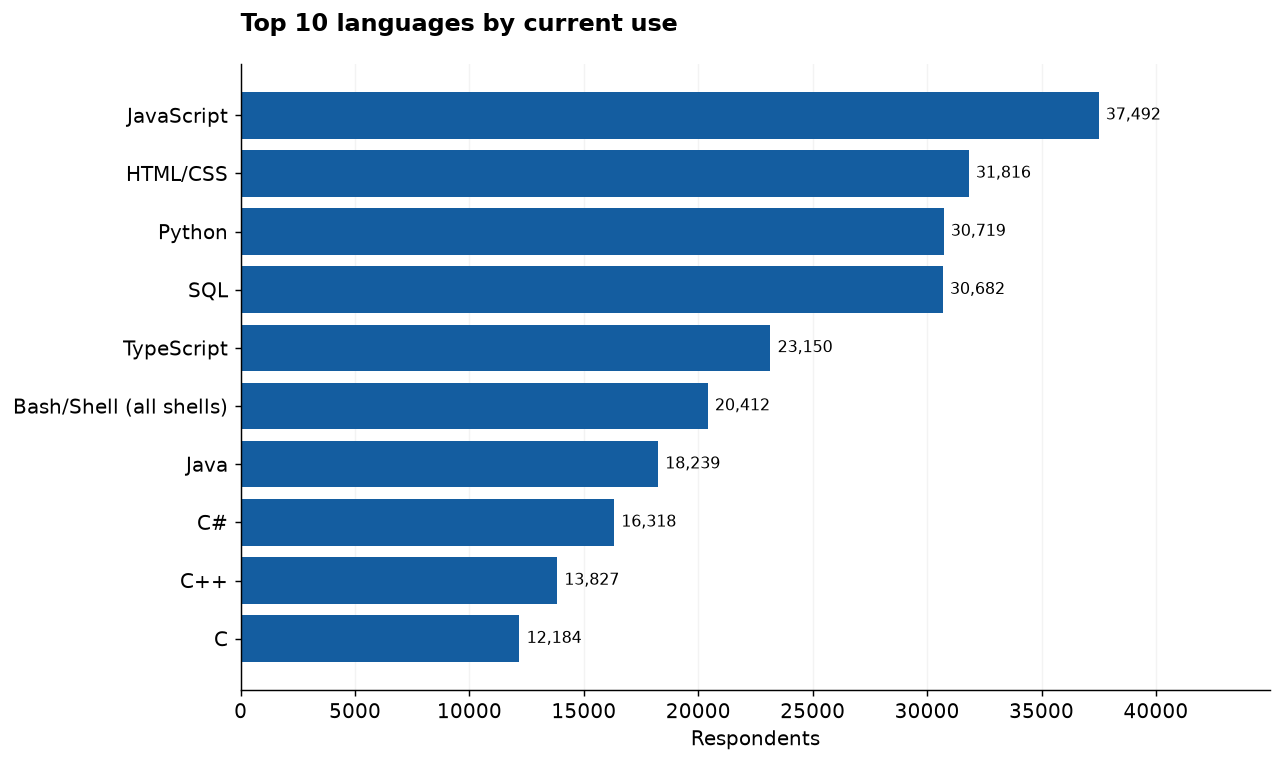

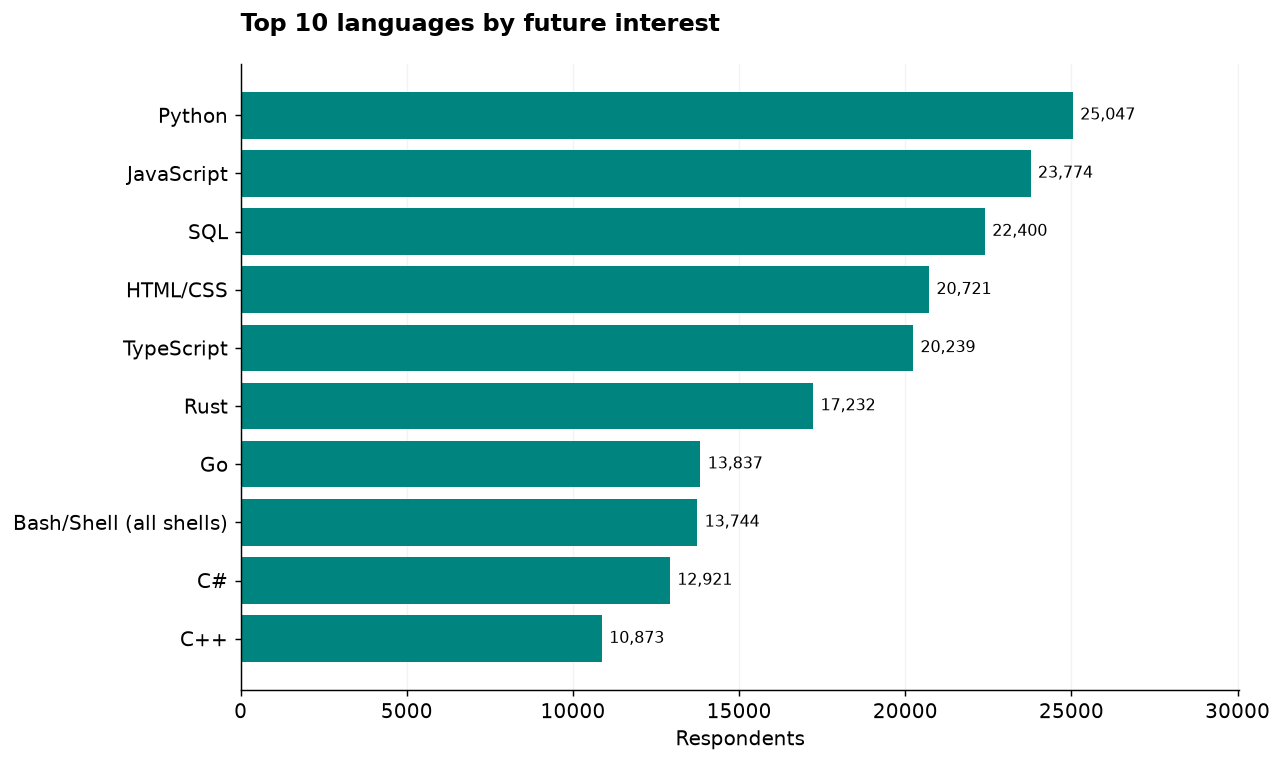

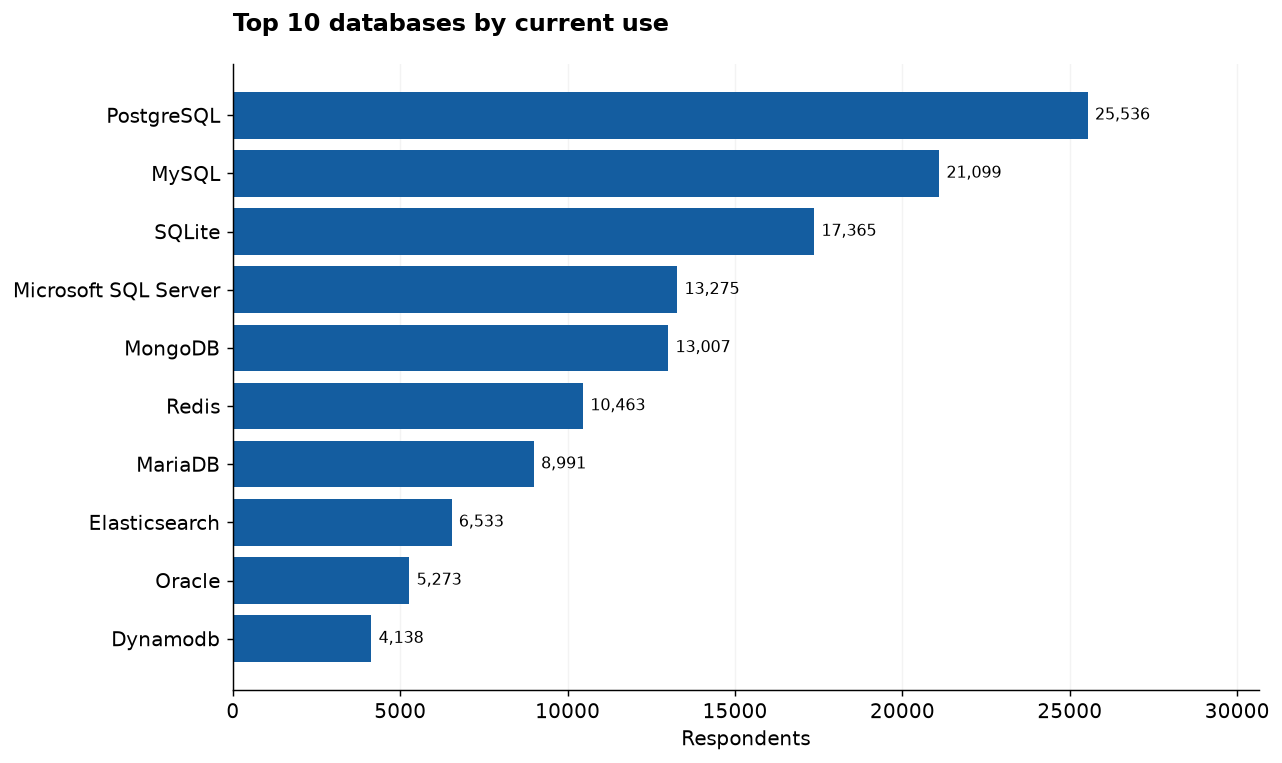

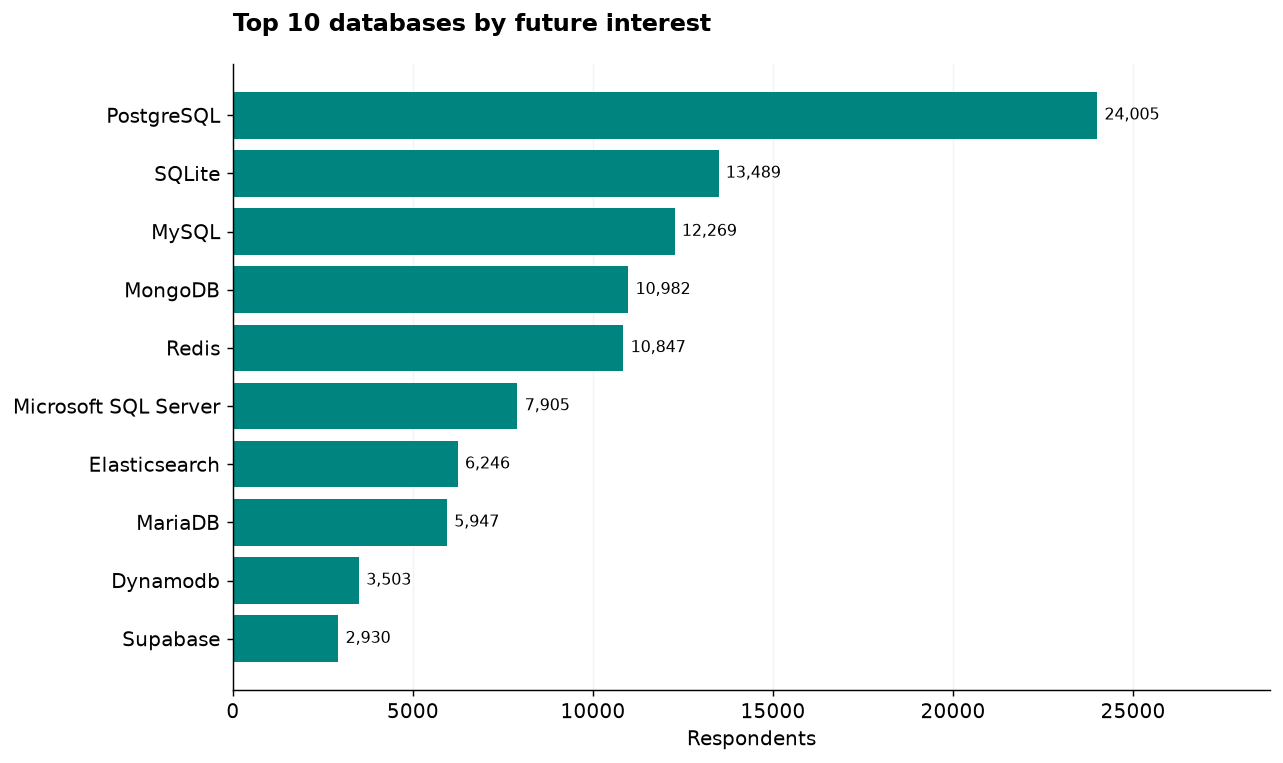

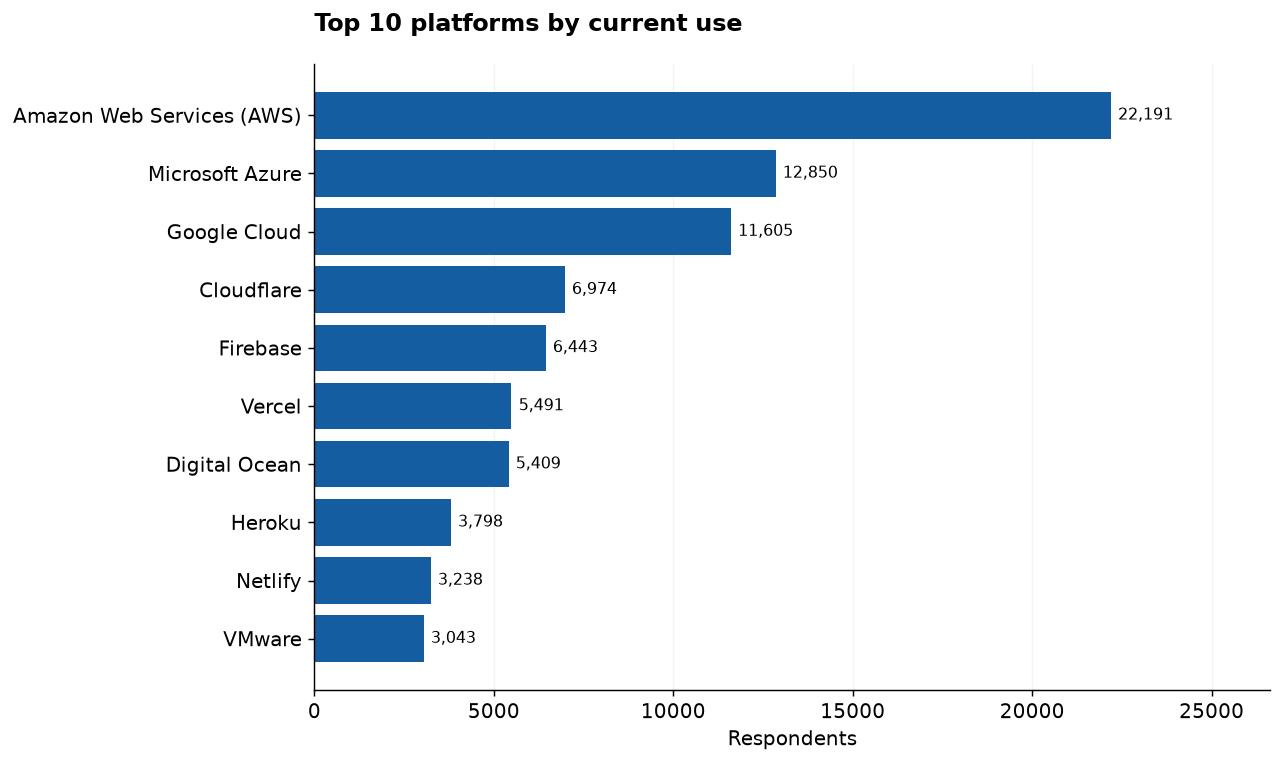

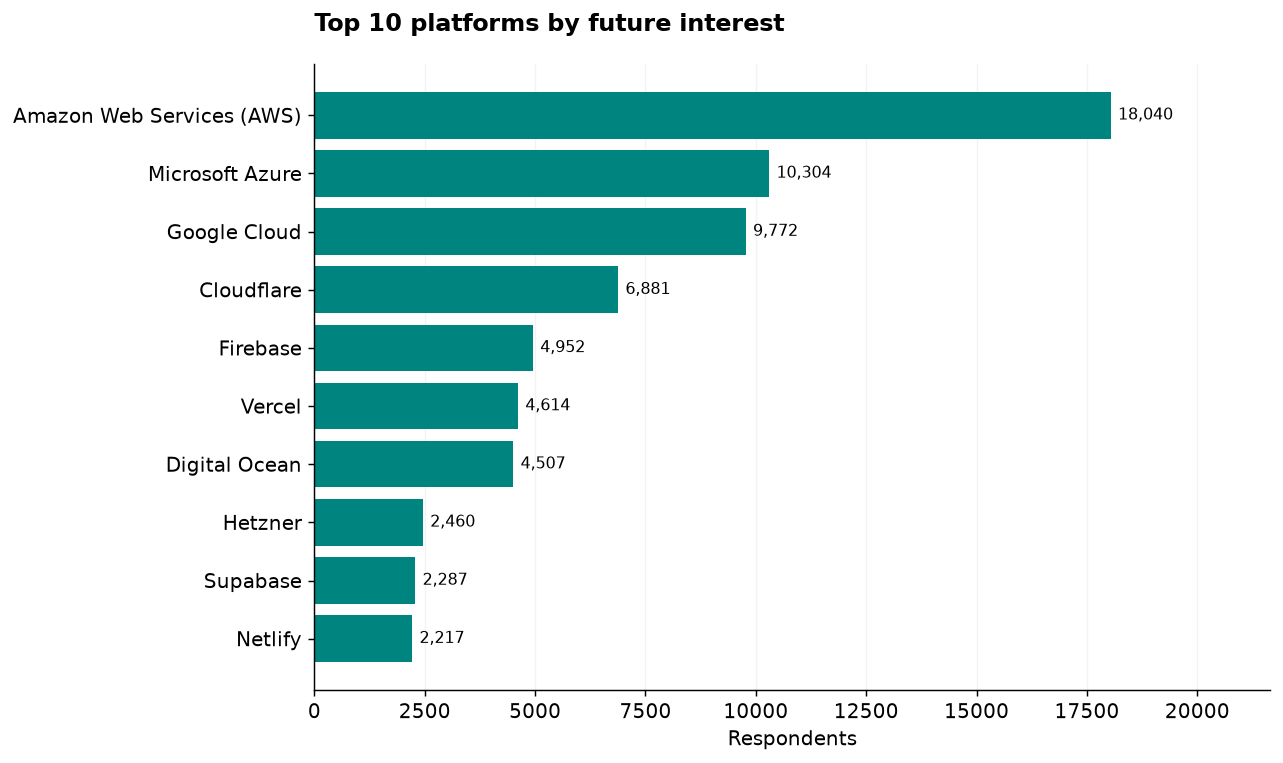

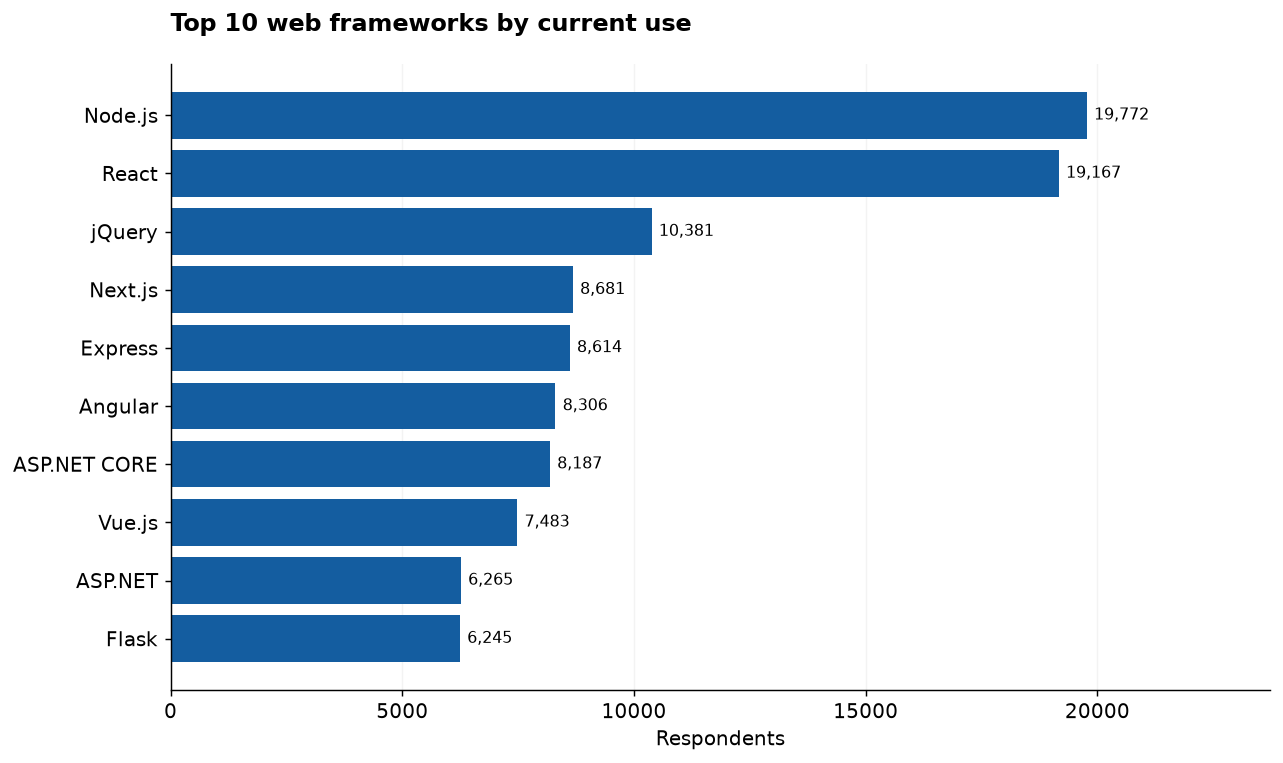

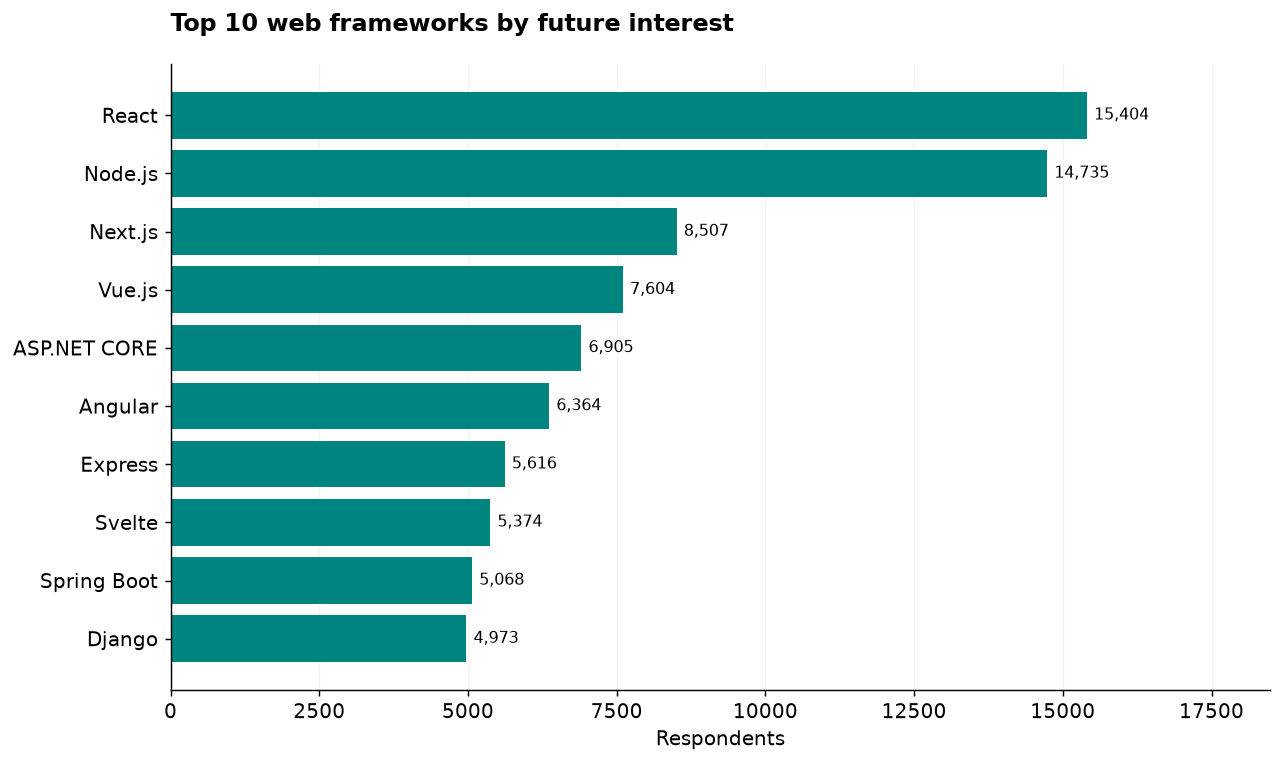

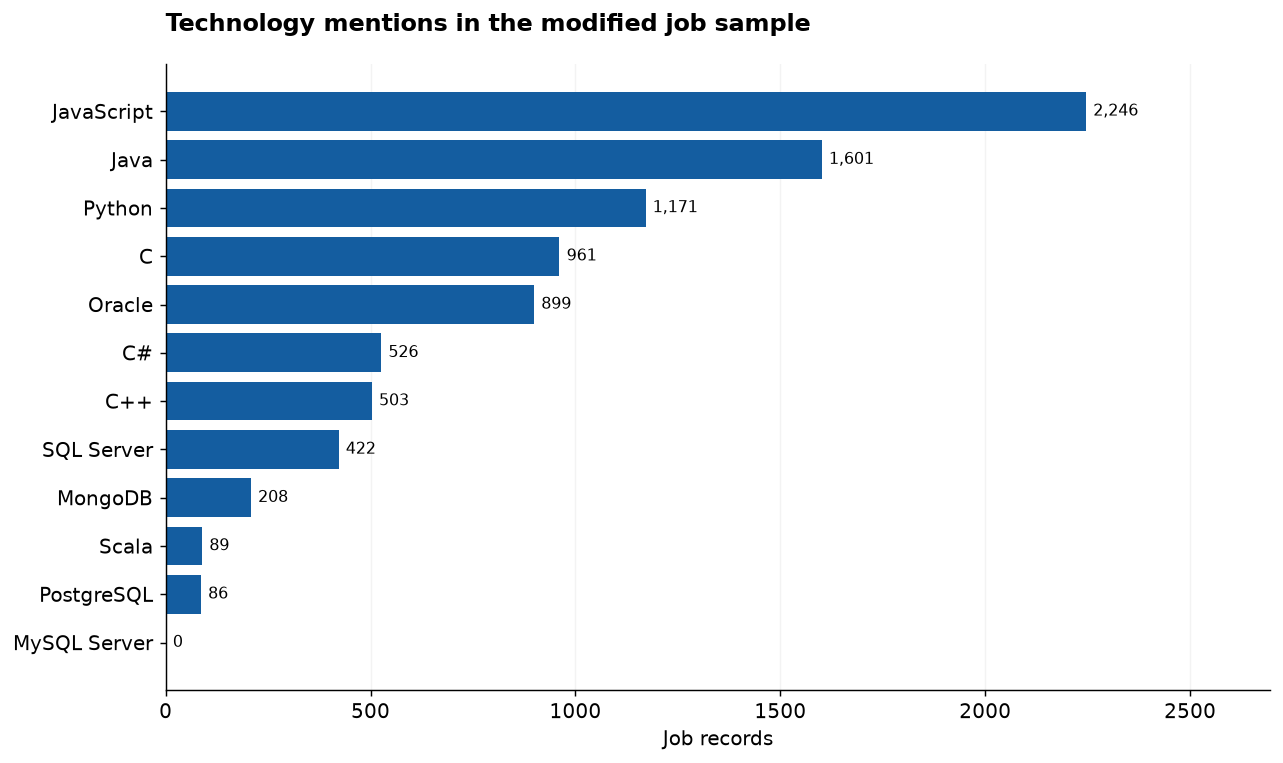

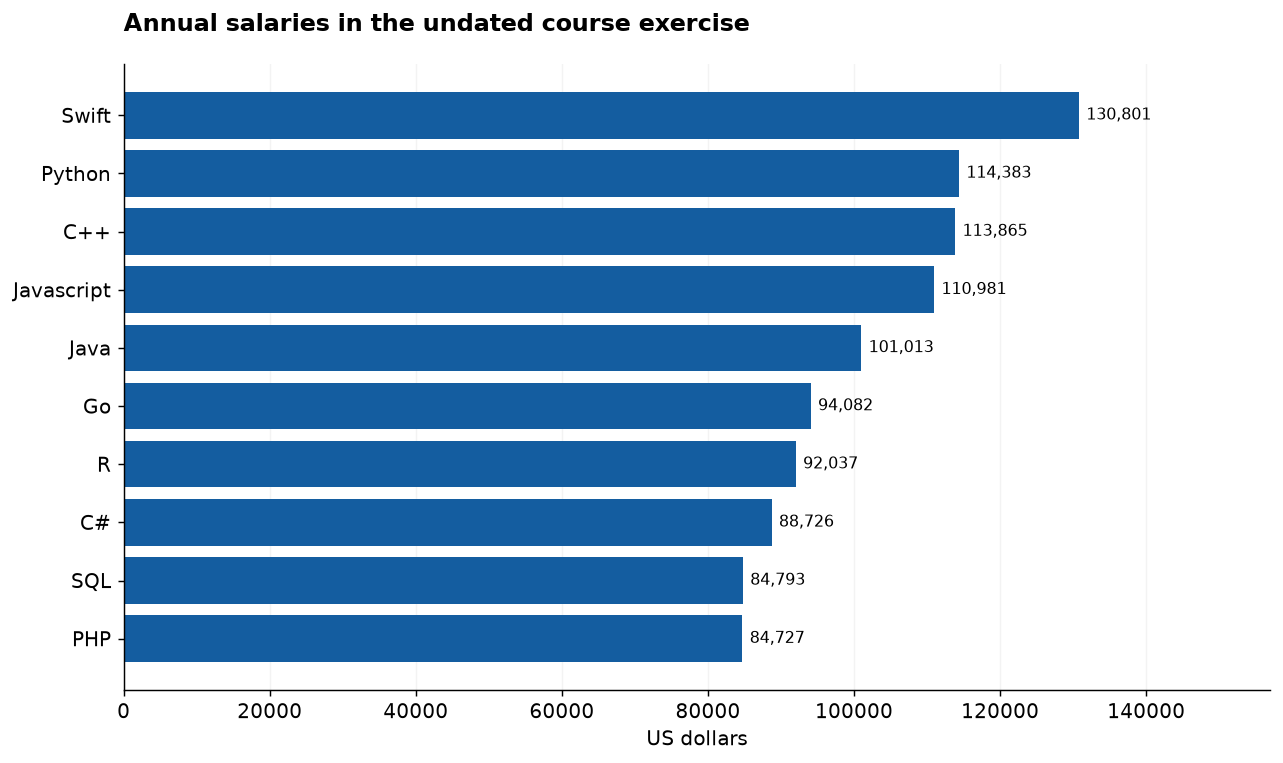

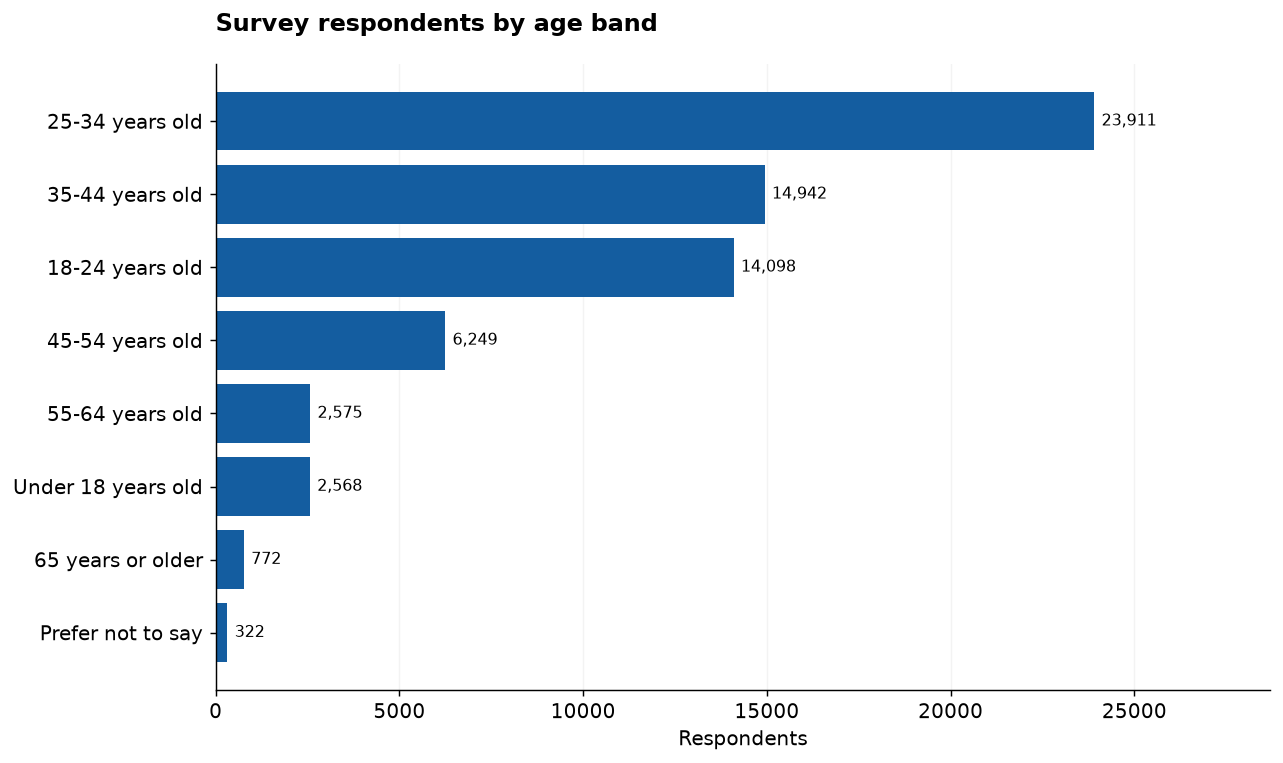

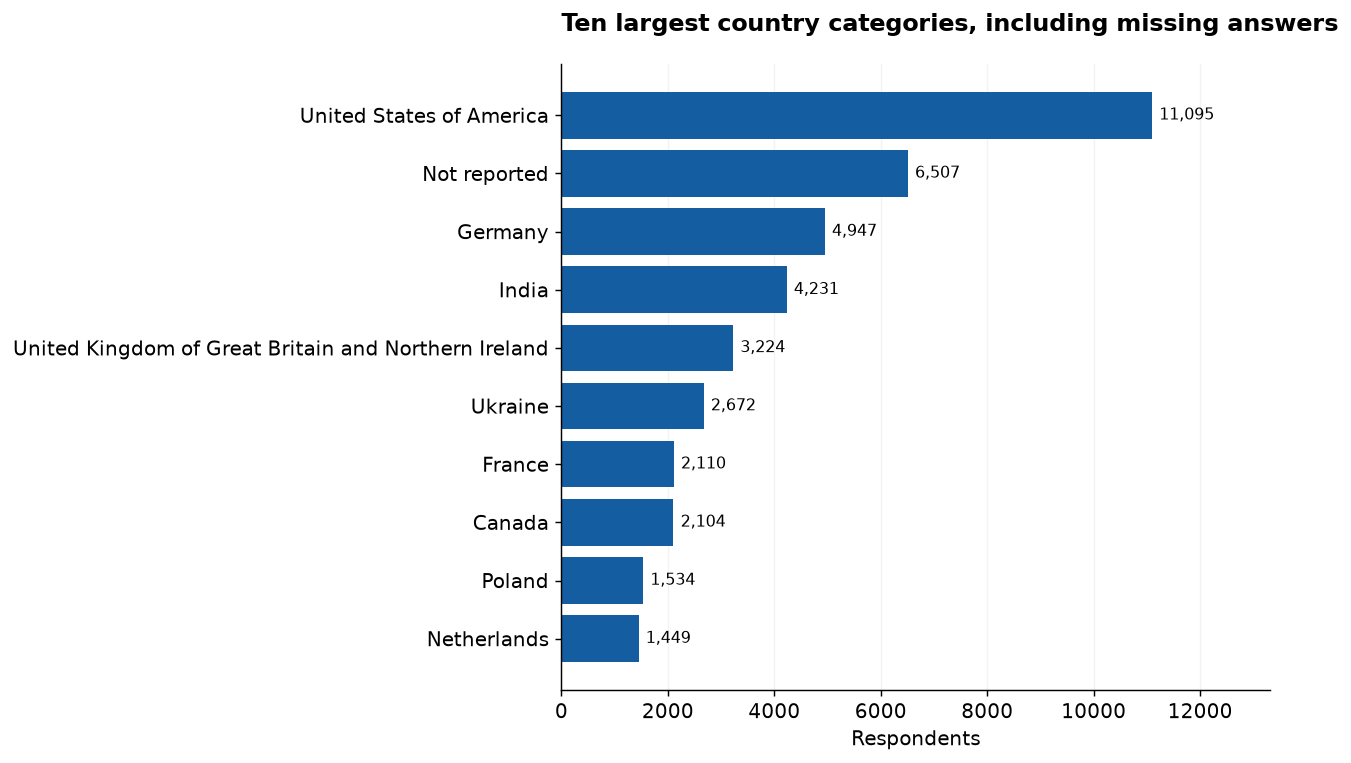

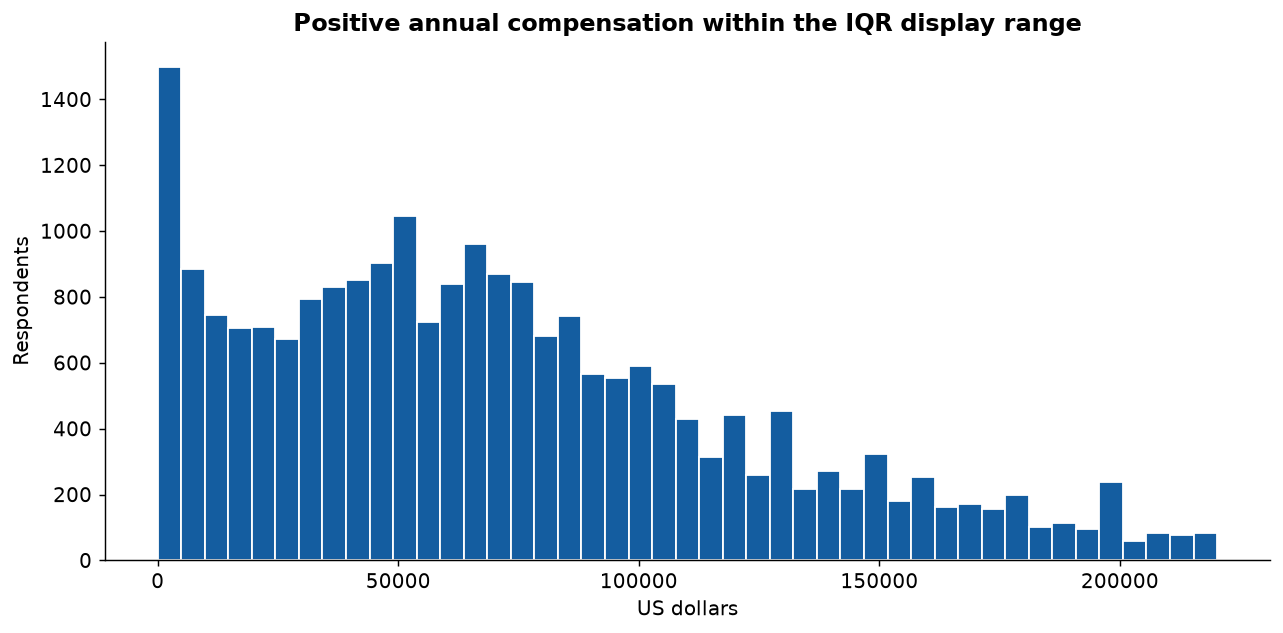

In [7]:
def bar_figure(labels, values, title, filename, xlabel='Respondents', color='#145da0'):
    order = np.argsort(np.asarray(values))
    fig, ax = plt.subplots(figsize=(10, 6))
    bars = ax.barh(np.asarray(labels)[order], np.asarray(values)[order], color=color)
    ax.set_title(title, loc='left', pad=18)
    ax.set_xlabel(xlabel)
    ax.bar_label(bars, fmt=lambda value: f'{value:,.0f}', padding=4, fontsize=9)
    ax.set_xlim(0, max(values) * 1.2)
    ax.grid(axis='x', alpha=.15)
    ax.set_axisbelow(True)
    fig.tight_layout()
    fig.savefig(FIGURES / filename, bbox_inches='tight')
    plt.show()
    plt.close(fig)

for family, table in trends.items():
    for mode, column in [('current', 'CurrentRespondents'), ('desired', 'DesiredRespondents')]:
        ranking = table.nlargest(10, column)
        bar_figure(ranking.index.to_list(), ranking[column].to_list(),
                   f'Top 10 {family.replace("_", " ")} by {mode} use' if mode == 'current' else f'Top 10 {family.replace("_", " ")} by future interest',
                   f'{family}_{mode}.png', color='#145da0' if mode == 'current' else '#00847f')
bar_figure(job_counts.Technology.to_list(), job_counts.BoundedMatches.to_list(),
           'Technology mentions in the modified job sample', 'job_technologies.png', 'Job records')
bar_figure(salary_table.Language.to_list(), salary_table.AnnualSalaryUSD.to_list(),
           'Annual salaries in the undated course exercise', 'exercise_salaries.png', 'US dollars')
bar_figure(demographics['age'].Category.to_list(), demographics['age'].Respondents.to_list(),
           'Survey respondents by age band', 'age_distribution.png')
country_top = demographics['country'].head(10)
bar_figure(country_top.Category.to_list(), country_top.Respondents.to_list(),
           'Ten largest country categories, including missing answers', 'country_distribution.png')
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(positive_compensation.loc[iqr_inliers], bins=45, color='#145da0', edgecolor='white')
ax.set(title='Positive annual compensation within the IQR display range', xlabel='US dollars', ylabel='Respondents')
fig.tight_layout()
fig.savefig(FIGURES / 'compensation_distribution.png', bbox_inches='tight')
plt.show()
plt.close(fig)

## Interactive portfolio dashboard

This self-contained HTML dashboard has current-use, future-interest and
demographic views. It is a local portfolio artifact. It is not represented
as an IBM Cognos or Google Looker dashboard or a completed graded submission.

In [8]:
chart_fragments = {}
for view, value_column in [('Current Technology Usage', 'CurrentRespondents'),
                           ('Future Technology Trends', 'DesiredRespondents')]:
    figure = make_subplots(rows=2, cols=2, subplot_titles=['Languages', 'Databases', 'Platforms', 'Web frameworks'],
                           horizontal_spacing=.23, vertical_spacing=.18)
    for index, (family, table) in enumerate(trends.items()):
        ranking = table.nlargest(10, value_column).sort_values(value_column)
        figure.add_trace(go.Bar(x=ranking[value_column], y=ranking.index, orientation='h',
                                marker_color='#145da0' if value_column == 'CurrentRespondents' else '#00847f',
                                hovertemplate='%{y}: %{x:,} respondents<extra></extra>'),
                         row=index // 2 + 1, col=index % 2 + 1)
    figure.update_layout(height=920, showlegend=False, template='plotly_white', margin=dict(l=190, r=60, b=65, t=70))
    figure.update_xaxes(title_text='Respondents')
    chart_fragments[view] = figure.to_html(full_html=False, include_plotlyjs=True if not chart_fragments else False)
figure = make_subplots(rows=2, cols=2, subplot_titles=['Age bands', 'Country categories', 'Education', 'Work arrangement'],
                       horizontal_spacing=.30, vertical_spacing=.2)
short_labels = {
    'United Kingdom of Great Britain and Northern Ireland': 'United Kingdom',
    'United States of America': 'United States',
    'Bachelor’s degree (B.A., B.S., B.Eng., etc.)': 'Bachelor’s degree',
    'Master’s degree (M.A., M.S., M.Eng., MBA, etc.)': 'Master’s degree',
    'Some college/university study without earning a degree': 'Some college, no degree',
    'Secondary school (e.g. American high school, German Realschule or Gymnasium, etc.)': 'Secondary school',
    'Professional degree (JD, MD, Ph.D, Ed.D, etc.)': 'Professional degree',
    'Associate degree (A.A., A.S., etc.)': 'Associate degree',
    'Hybrid (some remote, some in-person)': 'Hybrid',
}
for index, stem in enumerate(['age', 'country', 'education', 'work_mode']):
    ranking = demographics[stem].head(10).sort_values('Respondents')
    figure.add_trace(go.Bar(x=ranking.Respondents, y=ranking.Category.replace(short_labels),
                            customdata=ranking.Category, orientation='h', marker_color='#145da0',
                            hovertemplate='%{customdata}: %{x:,} respondents<extra></extra>'),
                     row=index // 2 + 1, col=index % 2 + 1)
figure.update_layout(height=1040, showlegend=False, template='plotly_white', margin=dict(l=200, r=60, b=70, t=70))
figure.update_xaxes(title_text='Respondents')
chart_fragments['Demographics'] = figure.to_html(full_html=False, include_plotlyjs=False)
panels = ''.join(f'<section id="view-{index}" class="view" {"hidden" if index else ""}>{content}</section>'
                 for index, content in enumerate(chart_fragments.values()))
buttons = ''.join(f'<button role="tab" aria-selected="{str(index == 0).lower()}" onclick="showView({index},this)">{name}</button>'
                  for index, name in enumerate(chart_fragments))
dashboard = f'''<!doctype html><html lang="en"><head><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1">
<title>Developer technology trends</title><style>body{{font:16px system-ui,sans-serif;color:#172b3a;background:#f6f8fb;margin:0}}main{{max-width:1550px;margin:auto;padding:32px}}h1{{font-size:32px;margin:0 0 10px}}.context{{max-width:1000px;line-height:1.6}}nav{{display:flex;gap:12px;flex-wrap:wrap;margin:28px 0}}button{{padding:12px 18px;border:1px solid #a6b7c7;border-radius:5px;background:white;font:inherit;cursor:pointer}}button[aria-selected=true]{{color:white;background:#145da0;border-color:#145da0}}section{{background:white;padding:10px;border-radius:5px}}footer{{font-size:14px;line-height:1.7;margin-top:22px}}[hidden]{{display:none}}</style></head>
<body><main><h1>Developer technology trends</h1><p class="context">IBM course copy of the 2024 Stack Overflow Developer Survey. {n:,} unique respondents after removing {duplicate_rows} duplicate rows. Charts count each technology once per respondent. Future interest reflects stated preferences.</p><nav role="tablist" aria-label="Dashboard views">{buttons}</nav>{panels}<footer>Percentages in the accompanying analysis use all {n:,} respondents. Missing answers remain missing. Country charts include “Not reported.” This survey sample is not a representative estimate of the worldwide developer population.<br>Source: <a href="https://survey.stackoverflow.co/2024/">Stack Overflow Developer Survey 2024</a>, course dataset under the Open Database License. Prepared with AI assistance.</footer></main>
<script>function showView(index,button){{document.querySelectorAll('.view').forEach((view,i)=>view.hidden=i!==index);document.querySelectorAll('[role=tab]').forEach(tab=>tab.setAttribute('aria-selected',tab===button?'true':'false'));window.dispatchEvent(new Event('resize'));}}</script></body></html>'''
(ROOT / 'dashboard.html').write_text(dashboard, encoding='utf-8')
print('Created dashboard.html with three interactive views.')

Created dashboard.html with three interactive views.


## Findings and limitations

Report ranks and observed interest differences without interpreting them as
causal effects or future adoption forecasts. Salary sources are kept separate.

In [9]:
languages = trends['languages']
databases = trends['databases']
top_current_language = languages['CurrentRespondents'].idxmax()
top_desired_language = languages['DesiredRespondents'].idxmax()
top_current_database = databases['CurrentRespondents'].idxmax()
top_desired_database = databases['DesiredRespondents'].idxmax()
findings = f'''# Developer technology trends

## Source coverage

The IBM course survey contains {len(raw):,} rows and {raw.shape[1]} columns. Removing {duplicate_rows} exact duplicate rows leaves {n:,} unique respondent IDs. Country is reported for {n-quality['missing_country']:,} respondents across {quality['countries']} countries. The job exercise contains {len(jobs):,} modified records. The salary exercise contains {len(salary_table)} languages and has no stated survey date or sample size.

## Observed technology preferences

{top_current_language} has the most current-use mentions: {int(languages.loc[top_current_language, 'CurrentRespondents']):,} respondents ({languages.loc[top_current_language, 'CurrentPct']:.1f}% of all respondents). {top_desired_language} leads future interest: {int(languages.loc[top_desired_language, 'DesiredRespondents']):,} respondents ({languages.loc[top_desired_language, 'DesiredPct']:.1f}%).

{top_current_database} leads current database use, and {top_desired_database} leads desired database use. Complete rankings and percentage-point comparisons are in the derived CSV files. Current use and future interest are answers to different questions in one survey year.

## Compensation and demographics

Positive annual compensation is available for {len(positive_compensation):,} respondents. Its median is ${positive_compensation.median():,.0f} in the supplied converted USD field. {quality['missing_compensation']:,} compensation values are missing. The histogram excludes {quality['compensation_iqr_outliers']:,} positive compensation responses outside the IQR display range, while the headline median uses every positive response. Age is categorical and does not support an exact mean age.

## Interpretation

The survey describes people who chose to respond. It does not establish representative global employment demand or a forecast of technology adoption. Future interest can identify topics worth comparing with current use, but country, experience and response coverage should be considered before applying these findings to a particular team.

The course API uses case-sensitive substrings, which can combine distinct technologies such as Java and JavaScript. The job-count CSV preserves those results and adds a case-insensitive comparison with term boundaries. These are counts within a modified teaching dataset. They are not current US city job totals.

The salary exercise has insufficient methodology for comparing career earnings. It is presented only as the result of extracting the supplied HTML table.

## Reproduction

Run `python src/download_data.py`, then `python src/analysis.py` from the repository. The notebook contains the same analysis. Raw respondent data is excluded from this repository. Source links and licensing are in README.md. This analysis was developed with AI assistance.
'''
(REPORTS / 'findings.md').write_text(findings, encoding='utf-8')
print(findings)

# Developer technology trends

## Source coverage

The IBM course survey contains 65,457 rows and 114 columns. Removing 20 exact duplicate rows leaves 65,437 unique respondent IDs. Country is reported for 58,930 respondents across 185 countries. The job exercise contains 27,005 modified records. The salary exercise contains 10 languages and has no stated survey date or sample size.

## Observed technology preferences

JavaScript has the most current-use mentions: 37,492 respondents (57.3% of all respondents). Python leads future interest: 25,047 respondents (38.3%).

PostgreSQL leads current database use, and PostgreSQL leads desired database use. Complete rankings and percentage-point comparisons are in the derived CSV files. Current use and future interest are answers to different questions in one survey year.

## Compensation and demographics

Positive annual compensation is available for 23,435 respondents. Its median is $65,000 in the supplied converted USD field. 42,002 compensat